In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

In [2]:
import sklearn
np.__version__, pd.__version__, sklearn.__version__

('2.4.3', '3.0.1', '1.8.0')

### Q1. 

In [ ]:
df = pd.read_csv("set_03_data.csv")
df.head(2)

In [ ]:
stat_mean = df["sales_idx"].mean()
stat_std  = df["sales_idx"].std()
stat_mean, stat_std

In [7]:
stat_out = stat_mean + 2 * stat_std
stat_out

np.float64(146.55150129273215)

In [10]:
df_q1 = df.loc[df["sales_idx"] > stat_out, ]
len(df_q1)

16

In [ ]:
df_q1["idx"] = (df_q1["ROM"] / 32) + (df_q1["RAM"] / 2) + (df_q1["n_front_cam"] + df_q1["n_rear_cam"])
df_q1["idx"] = df_q1["idx"] + (df_q1["battery_c"] / 1000)
df_q1.head(2)

In [15]:
round(df_q1["idx"].mean(), 2)

np.float64(11.01)

### Q2.

In [ ]:
df = pd.read_csv("set_03_data.csv")
df.head(2)

In [ ]:
df_q2 = df.drop(columns = "screen_size")
df_q2.head(2)

In [ ]:
arr_q2_nor = StandardScaler().fit_transform(df_q2)
arr_q2_nor[:2, ]

In [ ]:
df_q2_nor = pd.DataFrame(arr_q2_nor, columns = df_q2.columns)
df_q2_nor.head(2)

In [ ]:
model_kmeans = KMeans(n_clusters = 4, random_state = 123)
model_kmeans.fit(df_q2_nor)

In [24]:
df_c = pd.DataFrame(model_kmeans.cluster_centers_, columns = df_q2.columns)
df_c.round(2) # "battery_c" 변수의 값이 가장 큰!! 0.62!

,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,sales_idx
0,-0.29,-0.19,0.45,-0.19,0.62,-0.32,-0.07,-0.48,0.22,-0.08
1,-0.57,-0.84,-1.32,0.04,-1.12,0.89,0.28,0.23,-0.40,0.34
2,-0.53,-0.49,-0.95,0.91,-0.62,0.57,7.33,-0.62,0.33,7.48
3,1.13,1.17,0.27,0.34,-0.28,-0.15,-0.38,0.82,-0.12,-0.42


In [27]:
arr_dist = euclidean_distances(df_c)
arr_dist # 첫 번째 행 또는 열에 있는 2.66!!

array([[ 0.        ,  3.05863454, 10.83781422,  2.66304292],
       [ 3.05863454,  0.        , 10.16588612,  3.57042325],
       [10.83781422, 10.16588612,  0.        , 11.49910926],
       [ 2.66304292,  3.57042325, 11.49910926,  0.        ]])

### Q3.

In [28]:
df = pd.read_csv("set_03_data.csv")
df.head(2)

,screen_size,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,sales_idx
0,Very Small,64,2,1,1,1800,4.5,38645,32999,0.17,127.52
1,Small,64,4,2,1,2815,4.5,244,57149,0.04,1.39


`pd.get_dummies()`는 다른 메서드/함수/클래스와 다르게 "columns" 인자에 단일 값을 할당하는 경우에도 반드시 🌟**리스트**🌟 객체(또는 비슷한 유형)를 사용하여 할당해야 한다. 단순 문자열을 할당할 경우 에러가 난다.

그리고 원핫인코딩을 실시할 때 변수명에 띄어쓰기가 있을 수 있는데 `statsmodels` 라이브러리 기반 모델링을 하면서 formula 를 사용하는 경우 변수명에 띄어쓰기를 제거하지 않은 채로 formula를 작성하면 반드시 에러가 발생함. 그리고 이 이슈는 이전 시험에서 응시자가 어려움을 겪은 사례가 있음.  
※ 다음의 코드 결과에서는 "screen_size_Very Large"  
※ "screen_size_Very Large" -> "screen_size_Very_Large"

In [43]:
# 단계 1)
# df_q3_dum = pd.get_dummies(df, columns = ["screen_size"]) # 시험버전
df_q3_dum = pd.get_dummies(df, columns = ["screen_size"], dtype = "int") # 최신버전(Pandas 2.0 이상)
df_q3_dum = df_q3_dum.set_index("sales_idx").reset_index() # 모델링을 편하게 하기 위함.
df_q3_dum.head(2)

,sales_idx,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,screen_size_Large,screen_size_Medium,screen_size_Small,screen_size_Very Large,screen_size_Very Small
0,127.52,64,2,1,1,1800,4.5,38645,32999,0.17,0,0,0,0,1
1,1.39,64,4,2,1,2815,4.5,244,57149,0.04,0,0,1,0,0


In [44]:
# 단계 2)
df_train, df_test = train_test_split(df_q3_dum, train_size = 0.8, random_state = 123)
len(df_train), len(df_test)

(344, 86)

In [45]:
# 단계 3)
model_nor = MinMaxScaler().fit(df_train)
arr_train_nor = model_nor.transform(df_train)
arr_test_nor  = model_nor.transform(df_test)

In [46]:
arr_train_nor[:1, ]

array([[0.00394753, 0.04761905, 0.18181818, 0.33333333, 0.        ,
        0.42307692, 0.625     , 0.00396262, 0.02607261, 0.09302326,
        0.        , 0.        , 1.        , 0.        , 0.        ]])

In [ ]:
# 단계 4)
ls_k = [3, 5, 7, 9, 11]
k = ls_k[0]
model_knn = KNeighborsRegressor(n_neighbors = k)
model_knn.fit(X = arr_train_nor[:, 1:], # 첫 번째 열이 종속변수!!
              y = arr_train_nor[:, 0])
pred_knn = model_knn.predict(arr_test_nor[:, 1:])
mean_squared_error(y_true = arr_test_nor[:, 0], y_pred = pred_knn) ** 0.5

In [58]:
ls_k = [3, 5, 7, 9, 11]
ls_rmse = []
for k in ls_k: # 손으로 해도 됨 ㅎ
    model_knn = KNeighborsRegressor(n_neighbors = k)
    model_knn.fit(X = arr_train_nor[:, 1:], # 첫 번째 열이 종속변수!!
                  y = arr_train_nor[:, 0])
    pred_knn = model_knn.predict(arr_test_nor[:, 1:])
    val_rmse = mean_squared_error(y_true = arr_test_nor[:, 0], y_pred = pred_knn) ** 0.5
    ls_rmse = ls_rmse + [val_rmse]

In [ ]:
df_rmse = pd.DataFrame(dict(k = ls_k, rmse = ls_rmse)) # 굳이... 이렇게 까지 안해도 됨.
df_rmse.iloc[[df_rmse["rmse"].idxmin()], ]

In [65]:
k_best = 3

In [66]:
model_knn.n_neighbors # 현재 model_knn의 k는 11임!!!

11

In [ ]:
# 단계 5)
model_best = KNeighborsRegressor(n_neighbors = k_best)
model_best.fit(X = arr_train_nor[:, 1:],
               y = arr_train_nor[:, 0])

In [74]:
# 단계 6)
# 데이터를 직접 데이터프레임으로 만들어도 되고,
# test 세트에서 한 줄 떼와서 수정해도 됨.
# df_t1 = df_test.head(1).reset_index(drop = True)
df_t1 = pd.DataFrame([[0] * df_test.shape[1]], columns = df_test.columns)
df_t1["ROM"] = 256
df_t1["RAM"] = 6
df_t1["n_rear_cam"] = 4
df_t1["n_front_cam"] = 1
df_t1["battery_c"] = 4000
df_t1["ratings"] = 4.3
df_t1["n_ratings"] = 25000
df_t1["sales_p"] = 85000
df_t1["discount_p"] = 0.05
df_t1["screen_size_Large"] = 1
df_t1

,sales_idx,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,screen_size_Large,screen_size_Medium,screen_size_Small,screen_size_Very Large,screen_size_Very Small
0,0,256,6,4,1,4000,4.3,25000,85000,0.05,1,0,0,0,0


In [79]:
# 단계 7)
# model_nor.transform(df_t1.drop(columns = "sales_idx"))
arr_t1_nor = model_nor.transform(df_t1)
arr_t1_nor

array([[0.        , 0.49206349, 0.45454545, 1.        , 0.        ,
        0.42307692, 0.625     , 0.05308122, 0.51815842, 0.09302326,
        1.        , 0.        , 0.        , 0.        , 0.        ]])

In [81]:
# 단계 8)
pred_best_t1 = model_best.predict(arr_t1_nor[:, 1:])
pred_best_t1

array([0.00132259])

In [ ]:
# 단계 9)
# model_nor.inverse_transform(pred_best_t1)
# model_nor.inverse_transform([pred_best_t1])
# arr_t1_nor[0, 0] = pred_best_t1 # 시험버전
arr_t1_nor[0, 0] = pred_best_t1[0] # 최신버전
arr_t1_inv = model_nor.inverse_transform(arr_t1_nor)
arr_t1_inv

In [94]:
df_t1_inv = pd.DataFrame(arr_t1_inv, columns = df_t1.columns)
df_t1_inv # 0.65!!!

,sales_idx,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,screen_size_Large,screen_size_Medium,screen_size_Small,screen_size_Very Large,screen_size_Very Small
0,0.653333,256.0,6.0,4.0,1.0,4000.0,4.3,25000.0,85000.0,0.05,1.0,0.0,0.0,0.0,0.0


In [95]:
df_t1

,sales_idx,ROM,RAM,n_rear_cam,n_front_cam,battery_c,ratings,n_ratings,sales_p,discount_p,screen_size_Large,screen_size_Medium,screen_size_Small,screen_size_Very Large,screen_size_Very Small
0,0,256,6,4,1,4000,4.3,25000,85000,0.05,1,0,0,0,0


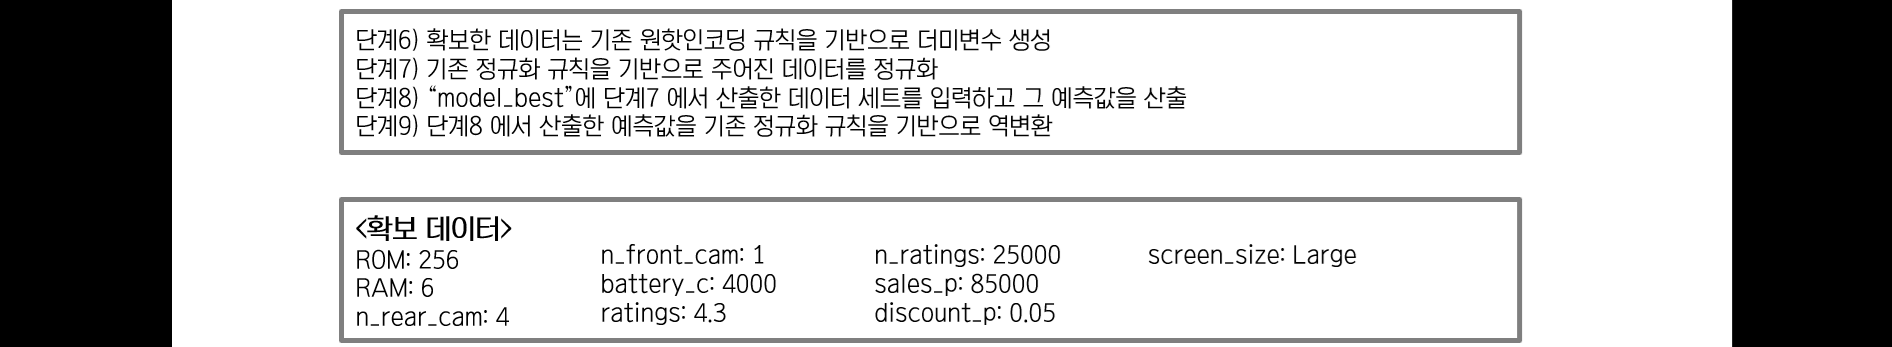